## Impact of query

In [1]:
import pandas as pd
import numpy as np

final_answers = pd.read_csv("Data/final_answer_df.csv")
queries = pd.read_csv("Data/query_formulation_df.csv")

In [2]:
final_answers.head()

,uid,topic_number,prompt,answer,TaskStartTime,TaskEndTime,TaskDuration,num_answer_matches,matched_keywords,answer_match_ratio
0,1,g3t3,Quali sono 5 animali tipici dell'India?,Rinoceronte tigre Leone stambecco cervo,2026-05-19 14:48:04.522,2026-05-19 14:56:19.153,8.243850,4,"['tigre', 'rinoceronte', 'leone', 'cervo']",0.8
1,1,g3t2,Qual è il nome del simbolo al centro della ban...,Il simbolo della bandiera rappresenta una ruota,2026-05-19 14:56:45.133,2026-05-19 15:06:18.848,9.561917,1,['ruota'],0.5
2,1,g3t1,Come si chiama il fiume sacro agli indiani?,Il fiume gange,2026-05-19 15:06:45.708,2026-05-19 15:10:10.812,3.418400,1,['gange'],1.0
3,2,g3t3,Quali sono 5 animali tipici dell'India?,"Tigre,leone,rinoceronte,barasingha,blackbuck.",2026-05-19 14:48:38.961,2026-05-19 14:58:07.578,9.476950,5,"['tigre', 'rinoceronte', 'leone', 'barasingha'...",1.0
4,2,g3t2,Qual è il nome del simbolo al centro della ban...,Ruota,2026-05-19 14:58:35.224,2026-05-19 15:10:30.790,11.926100,1,['ruota'],0.5


In [3]:
queries.head()

,uid,topic_number,qid,query,timestamp,serp_id,precision@10,query_len,mean_aoa,mean_conc,...,lex_diversity,ttr,stop_word_ratio,corrected_query,num_typos,levenshtein_dist,num_concepts,concepts,mean_concepts_conc,effective_query
0,1,g3t3,q1,Quali sono i cinque animali tipici dell india,2026-05-19 14:51:26.583,serp1,0.2,8,NaN,NaN,...,1.0,1.0,0.375000,NaN,0,0,3,"['Quali', 'i cinque animali tipici', 'india']",NaN,0
1,1,g3t2,q2,Quale è il nome del simbolo al centro della ba...,2026-05-19 15:02:41.120,serp2,0.1,11,5.12,5.3,...,1.0,1.0,0.545455,Quale è il nome del simbolo al centro della ba...,1,1,6,"['Quale', 'il nome', 'simbolo', 'centro', 'ban...",5.3,0
2,1,g3t1,q3,Fiume sacro degli indiani,2026-05-19 15:08:39.525,serp3,0.4,4,4.80,7.5,...,1.0,1.0,0.250000,NaN,0,0,2,"['Fiume sacro', 'indiani']",7.5,0
3,2,g3t3,q4,Quali sono i animali dall'India,2026-05-19 14:50:22.081,serp4,0.7,6,NaN,NaN,...,1.0,1.0,0.500000,NaN,0,0,3,"['Quali', 'i animali', 'India']",NaN,0
4,2,g3t3,q5,Quali sono i 5 animali tipici dall'India,2026-05-19 14:51:20.189,serp5,0.2,8,NaN,NaN,...,1.0,1.0,0.375000,NaN,0,0,3,"['Quali', 'i 5 animali tipici', 'India']",NaN,0


In [4]:
queries.columns

Index(['uid', 'topic_number', 'qid', 'query', 'timestamp', 'serp_id',
       'precision@10', 'query_len', 'mean_aoa', 'mean_conc', 'gulpease_index',
       'lex_density', 'lex_diversity', 'ttr', 'stop_word_ratio',
       'corrected_query', 'num_typos', 'levenshtein_dist', 'num_concepts',
       'concepts', 'mean_concepts_conc', 'effective_query'],
      dtype='object')

In [5]:
## query characteristics
num_queries = []
num_unique_queries = []

query_lex_density = []
query_aoa = []
query_gulpease_index = []
query_num_typos = []
query_lev_dist = []

query_len = []
query_num_concepts = []
query_conc = []
query_stop_words_ratio = []

query_p10 = []

for _, row in final_answers.iterrows():
    uid = row["uid"]
    topic_number = row["topic_number"]
    session_queries = queries.loc[(queries["uid"]==uid) & (queries["topic_number"]==topic_number)]
    num_queries.append(len(session_queries["query"]))
    num_unique_queries.append(len(set(session_queries["query"])))
    query_lex_density.append(session_queries["lex_density"].dropna().mean())
    query_aoa.append(session_queries["mean_aoa"].dropna().mean())
    query_gulpease_index.append(session_queries["gulpease_index"].dropna().mean())
    query_num_typos.append(session_queries["num_typos"].dropna().mean())
    query_lev_dist.append(session_queries["levenshtein_dist"].dropna().mean())
    query_len.append(session_queries["query_len"].dropna().mean())
    query_num_concepts.append(session_queries["num_concepts"].dropna().mean())
    query_conc.append(session_queries["mean_concepts_conc"].dropna().mean())
    query_stop_words_ratio.append(session_queries["stop_word_ratio"].dropna().mean())
    query_p10.append(session_queries["precision@10"].dropna().mean())

final_answers["num_queries"] = num_queries
final_answers["num_unique_queries"] = num_unique_queries

final_answers["query_lex_density"] = query_lex_density
final_answers["query_aoa"] = query_aoa
final_answers["query_gulpease_index"] = query_gulpease_index
final_answers["query_num_typos"] = query_num_typos
final_answers["query_lev_dist"] = query_lev_dist

final_answers["query_len"] = query_len
final_answers["query_num_concepts"] = query_num_concepts
final_answers["query_conc"] = query_conc
final_answers["query_stop_words_ratio"] = query_stop_words_ratio

final_answers["query_p10"] = query_p10

In [6]:
final_answers.to_csv("Data/final_answer_queries.csv", index=False, encoding="utf8")
final_answers.head()

,uid,topic_number,prompt,answer,TaskStartTime,TaskEndTime,TaskDuration,num_answer_matches,matched_keywords,answer_match_ratio,...,query_lex_density,query_aoa,query_gulpease_index,query_num_typos,query_lev_dist,query_len,query_num_concepts,query_conc,query_stop_words_ratio,query_p10
0,1,g3t3,Quali sono 5 animali tipici dell'India?,Rinoceronte tigre Leone stambecco cervo,2026-05-19 14:48:04.522,2026-05-19 14:56:19.153,8.243850,4,"['tigre', 'rinoceronte', 'leone', 'cervo']",0.8,...,0.500000,NaN,79.000000,0.0,0.0,8.0,3.0,NaN,0.375000,0.20
1,1,g3t2,Qual è il nome del simbolo al centro della ban...,Il simbolo della bandiera rappresenta una ruota,2026-05-19 14:56:45.133,2026-05-19 15:06:18.848,9.561917,1,['ruota'],0.5,...,0.545455,5.120000,69.909091,1.0,1.0,11.0,6.0,5.300,0.545455,0.10
2,1,g3t1,Come si chiama il fiume sacro agli indiani?,Il fiume gange,2026-05-19 15:06:45.708,2026-05-19 15:10:10.812,3.418400,1,['gange'],1.0,...,0.750000,4.800000,109.000000,0.0,0.0,4.0,2.0,7.500,0.250000,0.40
3,2,g3t3,Quali sono 5 animali tipici dell'India?,"Tigre,leone,rinoceronte,barasingha,blackbuck.",2026-05-19 14:48:38.961,2026-05-19 14:58:07.578,9.476950,5,"['tigre', 'rinoceronte', 'leone', 'barasingha'...",1.0,...,0.500000,NaN,89.142857,0.0,0.0,7.0,3.0,NaN,0.437500,0.45
4,2,g3t2,Qual è il nome del simbolo al centro della ban...,Ruota,2026-05-19 14:58:35.224,2026-05-19 15:10:30.790,11.926100,1,['ruota'],0.5,...,0.472222,5.066667,64.000000,1.5,1.5,15.0,6.5,6.575,0.500000,0.40


## Impact of SERP navigation

In [4]:
import pandas as pd

final_answers = pd.read_csv("Data/final_answer_df.csv")
serp = pd.read_csv("Data/results_navigation.csv")
navigation_quality = pd.read_csv("Data/navigation_quality.csv")
results_navigation = pd.read_csv("Data/results_navigation.csv")

viewed_results = pd.read_csv("Data/viewed_results_df.csv")
viewed_results["timestamp"] = pd.to_datetime(viewed_results["timestamp"])

explored_pages = pd.read_csv("Data/explored_pages.csv")
explored_pages["click_time"] = pd.to_datetime(explored_pages["click_time"])

partial_answers = pd.read_csv("Data/information_distillation_df.csv")
corpus = pd.read_excel("Data/analysed_corpus.xlsx")
relevance = pd.read_csv("Data/relevance.csv")

In [5]:
navigation_quality.columns

Index(['uid', 'topic_number', 'qid', 'query', 'serp_id', 'total_clicks',
       'repetitions', 'tail', 'last_relevant_timestamp', 'click_accuracy',
       'effective_navigation', 'first_click_time',
       'avg_scroll_time_before_click', 'avg_snippet_dwell_time_before_click',
       'avg_snippet_view_counts_before_click', 'rank_lowest_view',
       'viewed_avg_aoa', 'viewed_avg_conc', 'viewed_avg_length',
       'viewed_avg_gulpease_index', 'no_view_avg_aoa', 'no_view_avg_conc',
       'no_view_avg_length', 'no_view_avg_gulpease_index',
       'no_view_results_ratio', 'SERP_avg_aoa', 'SERP_avg_conc',
       'SERP_avg_gulpease_index', 'SERP_avg_length', 'SERP_total_results',
       'SERP_highest_rel_result'],
      dtype='object')

In [6]:
results_navigation.columns

Index(['uid', 'topic_number', 'qid', 'query', 'serp_id', 'url', 'title',
       'snippet', 'rank', 'relevance_score', 'click_count', 'timestamp',
       'SERP_result', 'SERP_result_content_len', 'SERP_result_mean_aoa',
       'SERP_result_mean_conc', 'SERP_result_gulpease_index', 'view_count'],
      dtype='object')

In [7]:
viewed_results.head(5)

,uid,topic_number,query,url,rank,viewType,viewDurationInSeconds,timestamp,serp_id,associated_click_timestamp
0,1,g3t3,Quali sono i cinque animali tipici dell india,https://wwftravel.it/blog/viaggi/india-natura-...,1,resultExposureStarted,NaN,2026-05-19 14:51:27.960,serp1,2026-05-19 14:51:43.444
1,1,g3t3,Quali sono i cinque animali tipici dell india,https://www.terreincognitemagazine.it/natura-s...,2,resultExposureStarted,NaN,2026-05-19 14:51:27.966,serp1,2026-05-19 14:51:43.444
2,1,g3t3,Quali sono i cinque animali tipici dell india,https://www.storicang.it/a/civilta-dellindo-i-...,3,resultExposureStarted,NaN,2026-05-19 14:51:31.168,serp1,2026-05-19 14:51:43.444
3,1,g3t3,Quali sono i cinque animali tipici dell india,https://wwftravel.it/blog/viaggi/india-natura-...,1,resultExposureEnded,15.730,2026-05-19 14:51:43.438,serp1,2026-05-19 14:51:43.444
4,1,g3t3,Quali sono i cinque animali tipici dell india,https://www.terreincognitemagazine.it/natura-s...,2,resultExposureEnded,15.731,2026-05-19 14:51:43.440,serp1,2026-05-19 14:51:43.444


In [8]:
explored_pages.head(5)

,uid,topic_number,url,exploreType,viewDurationInSeconds,timestamp,click_time,serp_id,click_rank,relevance_score
0,1,g3t3,https://wwftravel.it/blog/viaggi/india-natura-...,webpageClosed,76.920,2026-05-19 14:53:00.984,2026-05-19 14:51:43.444,serp1,1,1
1,1,g3t3,https://wwftravel.it/blog/viaggi/india-natura-...,webpageClosed,179.125,2026-05-19 14:56:19.147,2026-05-19 14:53:19.408,serp1,1,1
2,1,g3t2,https://it.gov-civ-guarda.pt/flag-india,webpageClosed,209.602,2026-05-19 15:06:18.840,2026-05-19 15:02:48.776,serp2,1,1
3,1,g3t1,https://www.consciousjourneys.com/it/approfond...,webpageClosed,36.112,2026-05-19 15:09:35.012,2026-05-19 15:08:58.405,serp3,2,1
4,2,g3t3,https://wwftravel.it/blog/viaggi/india-natura-...,webpageClosed,313.304,2026-05-19 14:58:07.573,2026-05-19 14:52:53.759,serp5,1,1


In [9]:
## SERP characteristics

SERP_dwell_time = []
snippet_dwell_time = []

view_depth = []
view_repeat = []
unique_view_count = []

viewed_aoa = []
viewed_len = []
viewed_gulpease_index = []
viewed_conc = []

for _, row in final_answers.iterrows():
    uid = row["uid"]
    topic_number = row["topic_number"]
    session_serp_nav = navigation_quality.loc[(navigation_quality["uid"]==uid) & (navigation_quality["topic_number"]==topic_number)]
    session_serps = results_navigation.loc[(results_navigation["uid"]==uid) & (results_navigation["topic_number"]==topic_number)]
    session_views = viewed_results.loc[(viewed_results["uid"]==uid) & (viewed_results["topic_number"]==topic_number)]

    viewed_snippets = session_serps.loc[session_serps["view_count"]>0]
    unique_views = list(viewed_snippets["url"].unique())

    serp_dwell_times = []
    serp_snippet_dwell_time = []
    for serp_id in session_views["serp_id"].unique():
        serp_views = session_views.loc[session_views["serp_id"]==serp_id]

        serp_snippet_dwell_time.append(serp_views.loc[serp_views["viewType"]=="resultExposureEnded"]["viewDurationInSeconds"].sum()/len(serp_views["url"].unique()))

        serp_explored_pages = explored_pages.loc[explored_pages["serp_id"]==serp_id]
        if serp_explored_pages["click_time"].max() > serp_views["timestamp"].max():
            serp_dwell_time = ((serp_views["timestamp"].max() - serp_views["timestamp"].min()).total_seconds()) - serp_explored_pages[:-1]["viewDurationInSeconds"].sum()
        else:
            serp_dwell_time = ((serp_views["timestamp"].max() - serp_views["timestamp"].min()).total_seconds()) - serp_explored_pages["viewDurationInSeconds"].sum()
            
        if serp_dwell_time < 0:
            print(serp_id)
            raise ValueError("The total time spent on the SERP is less than the time spent engaging with the resources clicked on the SERP")
        elif serp_dwell_time == 0:
            print(serp_id)
            raise ValueError("The total time spent on the SERP is equal to the time spent engaging with the resources clicked on the SERP")
        else:
            serp_dwell_times.append(serp_dwell_time)

    unique_view_snippets = viewed_snippets.drop_duplicates(subset=["url"])
    viewed_aoa.append(unique_view_snippets["SERP_result_mean_aoa"].mean())
    viewed_len.append(unique_view_snippets["SERP_result_content_len"].mean())
    viewed_gulpease_index.append(unique_view_snippets["SERP_result_gulpease_index"].mean())
    viewed_conc.append(unique_view_snippets["SERP_result_mean_conc"].mean())
    
    SERP_dwell_time.append(sum(serp_dwell_times)/len(session_views["serp_id"].unique()))  
    snippet_dwell_time.append(sum(serp_snippet_dwell_time)/len(session_views["serp_id"].unique())) 
    view_depth.append(session_serp_nav["rank_lowest_view"].mean())
    unique_view_count.append(len(unique_views))
    view_repeat.append((viewed_snippets["view_count"].sum() - len(unique_views))/len(unique_views))

final_answers["SERP_dwell_time"] = SERP_dwell_time
final_answers["snippet_dwell_time"] = snippet_dwell_time
final_answers["viewed_aoa"] = viewed_aoa
final_answers["viewed_len"] = viewed_len
final_answers["viewed_gulpease_index"] = viewed_gulpease_index
final_answers["viewed_conc"] = viewed_conc
final_answers["view_depth"] = view_depth
final_answers["view_repeat"] = view_repeat
final_answers["unique_view_count"] = unique_view_count

In [10]:
final_answers.to_csv("Data/final_answer_serp.csv", index=False, encoding="utf8")
final_answers.head()

,uid,topic_number,prompt,answer,TaskStartTime,TaskEndTime,TaskDuration,num_answer_matches,matched_keywords,answer_match_ratio,SERP_dwell_time,snippet_dwell_time,viewed_aoa,viewed_len,viewed_gulpease_index,viewed_conc,view_depth,view_repeat,unique_view_count
0,1,g3t3,Quali sono 5 animali tipici dell'India?,Rinoceronte tigre Leone stambecco cervo,2026-05-19 14:48:04.522,2026-05-19 14:56:19.153,8.243850,4,"['tigre', 'rinoceronte', 'leone', 'cervo']",0.8,34.5260,9.360400,5.632918,33.9,66.377603,6.431042,10.0,0.80,10
1,1,g3t2,Qual è il nome del simbolo al centro della ban...,Il simbolo della bandiera rappresenta una ruota,2026-05-19 14:56:45.133,2026-05-19 15:06:18.848,9.561917,1,['ruota'],0.5,5.9300,6.181000,4.690000,32.0,61.852665,6.150000,1.0,0.00,1
2,1,g3t1,Come si chiama il fiume sacro agli indiani?,Il fiume gange,2026-05-19 15:06:45.708,2026-05-19 15:10:10.812,3.418400,1,['gange'],1.0,53.1110,52.303000,4.775000,37.5,47.423141,7.241667,2.0,1.00,2
3,2,g3t3,Quali sono 5 animali tipici dell'India?,"Tigre,leone,rinoceronte,barasingha,blackbuck.",2026-05-19 14:48:38.961,2026-05-19 14:58:07.578,9.476950,5,"['tigre', 'rinoceronte', 'leone', 'barasingha'...",1.0,74.3710,40.349768,5.333060,33.6,73.307198,6.723095,5.5,0.70,10
4,2,g3t2,Qual è il nome del simbolo al centro della ban...,Ruota,2026-05-19 14:58:35.224,2026-05-19 15:10:30.790,11.926100,1,['ruota'],0.5,10.0435,8.655917,5.179167,35.0,64.054419,6.657083,2.5,0.25,4


## Impact of page engagement

In [16]:
import pandas as pd

final_answers = pd.read_csv("Data/final_answer_df.csv")
serp = pd.read_csv("Data/results_navigation.csv")
navigation_quality = pd.read_csv("Data/navigation_quality.csv")

explored_pages = pd.read_csv("Data/explored_pages.csv")
partial_answers = pd.read_csv("Data/information_distillation_df.csv")
corpus = pd.read_excel("Data/analysed_corpus.xlsx")
relevance = pd.read_csv("Data/relevance.csv")

In [17]:
explored_pages.head()

,uid,topic_number,url,exploreType,viewDurationInSeconds,timestamp,click_time,serp_id,click_rank,relevance_score
0,1,g3t3,https://wwftravel.it/blog/viaggi/india-natura-...,webpageClosed,76.920,2026-05-19 14:53:00.984,2026-05-19 14:51:43.444,serp1,1,1
1,1,g3t3,https://wwftravel.it/blog/viaggi/india-natura-...,webpageClosed,179.125,2026-05-19 14:56:19.147,2026-05-19 14:53:19.408,serp1,1,1
2,1,g3t2,https://it.gov-civ-guarda.pt/flag-india,webpageClosed,209.602,2026-05-19 15:06:18.840,2026-05-19 15:02:48.776,serp2,1,1
3,1,g3t1,https://www.consciousjourneys.com/it/approfond...,webpageClosed,36.112,2026-05-19 15:09:35.012,2026-05-19 15:08:58.405,serp3,2,1
4,2,g3t3,https://wwftravel.it/blog/viaggi/india-natura-...,webpageClosed,313.304,2026-05-19 14:58:07.573,2026-05-19 14:52:53.759,serp5,1,1


In [18]:
serp.columns

Index(['uid', 'topic_number', 'qid', 'query', 'serp_id', 'url', 'title',
       'snippet', 'rank', 'relevance_score', 'click_count', 'timestamp',
       'SERP_result', 'SERP_result_content_len', 'SERP_result_mean_aoa',
       'SERP_result_mean_conc', 'SERP_result_gulpease_index', 'view_count'],
      dtype='object')

In [19]:
corpus.columns

Index(['doc_id', 'url', 'html_content', 'text_content', 'scraping_source',
       'content_len', 'mean_aoa', 'mean_conc', 'gulpease_index'],
      dtype='object')

In [20]:
relevance.head()

,topic_number,topic,doc,relevance
0,g3t1,Fiume sacro India,https://liceoberchet.edu.it/ricerche/geo5d_06/...,1
1,g3t1,Fiume sacro India,https://www.latitudeslife.com/2011/10/india-cr...,1
2,g3t1,Fiume sacro India,https://www.esa.int/Space_in_Member_States/Ita...,1
3,g3t1,Fiume sacro India,https://www.beyondthetrip.net/2019/04/03/fiume...,1
4,g3t1,Fiume sacro India,https://www.goasia.it/la-religione-gange-fiume...,1


In [21]:
navigation_quality.columns

Index(['uid', 'topic_number', 'qid', 'query', 'serp_id', 'total_clicks',
       'repetitions', 'tail', 'last_relevant_timestamp', 'click_accuracy',
       'effective_navigation', 'first_click_time',
       'avg_scroll_time_before_click', 'avg_snippet_dwell_time_before_click',
       'avg_snippet_view_counts_before_click', 'rank_lowest_view',
       'viewed_avg_aoa', 'viewed_avg_conc', 'viewed_avg_length',
       'viewed_avg_gulpease_index', 'no_view_avg_aoa', 'no_view_avg_conc',
       'no_view_avg_length', 'no_view_avg_gulpease_index',
       'no_view_results_ratio', 'SERP_avg_aoa', 'SERP_avg_conc',
       'SERP_avg_gulpease_index', 'SERP_avg_length', 'SERP_total_results',
       'SERP_highest_rel_result'],
      dtype='object')

In [23]:
## Resource characteristics

explored_pages = explored_pages.loc[explored_pages["exploreType"]=="webpageClosed"]

num_unique_explored_pages = []
page_repeats = []
click_accuracy = []
click_recall = []

page_dwell_time = []
rel_page_dwell_time = []
irrel_page_dwell_time = []
ratio_rel_total_page_dwell_time = []

page_aoa = []
page_len = []
page_conc = []
page_gulpease_index = []

rel_page_aoa = []
rel_page_len = []
rel_page_conc = []
rel_page_gulpease_index = []

for _, row in final_answers.iterrows():
    uid = row["uid"]
    topic_number = row["topic_number"]
    session_explored_pages = explored_pages.loc[(explored_pages["uid"]==uid) & (explored_pages["topic_number"]==topic_number)]
    session_serp_navs = navigation_quality.loc[(navigation_quality["uid"]==uid) & (navigation_quality["topic_number"]==topic_number)]
    # print(uid, topic_number, len(session_explored_pages))
    corpus_pages = corpus.loc[corpus["url"].isin(set(session_explored_pages["url"]))]

    num_explored_pages = len(session_explored_pages)

    unique_pages = set(session_explored_pages["url"])
    num_unique_explored_pages.append(len(unique_pages))


    page_aoa.append(corpus_pages["mean_aoa"].dropna().mean())
    page_len.append(corpus_pages["content_len"].dropna().mean())
    page_conc.append(corpus_pages["mean_conc"].dropna().mean())
    page_gulpease_index.append(corpus_pages["gulpease_index"].dropna().mean())

    rel_pages = []
    irrel_pages = []
    page_dwell = []
    rel_page_dwell = []
    irrel_page_dwell = []

    for _, page in session_explored_pages.iterrows():
        url = page["url"]
        if page["relevance_score"] == 1:
            rel_page_dwell.append(page["viewDurationInSeconds"])
            rel_pages.append(url)
        elif page["relevance_score"] == 0:
            irrel_page_dwell.append(page["viewDurationInSeconds"])
            irrel_pages.append(url)
        else:
            print("Page has no relevance score??", page)
        page_dwell.append(page["viewDurationInSeconds"])

    if len(unique_pages) == 0:
        page_dwell_time.append(None)
        rel_page_dwell_time.append(None)
        irrel_page_dwell_time.append(None)
        ratio_rel_total_page_dwell_time.append(None)
        page_repeats.append(None)
    else:
        page_repeats.append((num_explored_pages - len(unique_pages))/len(unique_pages))
        page_dwell_time.append(np.mean(page_dwell))
        rel_page_dwell_time.append(np.mean(rel_page_dwell))
        irrel_page_dwell_time.append(np.mean(irrel_page_dwell))
        ratio_rel_total_page_dwell_time.append(sum(rel_page_dwell)/sum(page_dwell))

    click_accuracy.append(session_serp_navs["click_accuracy"].dropna().mean())
    click_recall.append(len(set(rel_pages))/len(relevance.loc[relevance["topic_number"]==topic_number]["doc"].unique()))

    corpus_rel_pages = corpus_pages.loc[corpus_pages["url"].isin(set(rel_pages))]
    rel_page_aoa.append(corpus_rel_pages["mean_aoa"].dropna().mean())
    rel_page_len.append(corpus_rel_pages["content_len"].dropna().mean())
    rel_page_conc.append(corpus_rel_pages["mean_conc"].dropna().mean())
    rel_page_gulpease_index.append(corpus_rel_pages["gulpease_index"].dropna().mean())

final_answers["page_repeats"] = page_repeats
final_answers["num_unique_explored_pages"] = num_unique_explored_pages
final_answers["click_accuracy"] = click_accuracy
final_answers["click_recall"] = click_recall

final_answers["page_dwell_time"] = page_dwell_time
final_answers["rel_page_dwell_time"] = rel_page_dwell_time
final_answers["irrel_page_dwell_time"] = irrel_page_dwell_time
final_answers["ratio_rel_total_page_dwell_time"] = ratio_rel_total_page_dwell_time

final_answers["page_aoa"] = page_aoa
final_answers["page_len"] = page_len
final_answers["page_conc"] = page_conc
final_answers["page_gulpease_index"] = page_gulpease_index

final_answers["rel_page_aoa"] = rel_page_aoa
final_answers["rel_page_len"] = rel_page_len
final_answers["rel_page_conc"] = rel_page_conc
final_answers["rel_page_gulpease_index"] = rel_page_gulpease_index

c:\Users\hrishitachakra\AppData\Local\anaconda3\envs\pt_env\lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\hrishitachakra\AppData\Local\anaconda3\envs\pt_env\lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [24]:
final_answers.to_csv("Data/final_answer_pages.csv", index=False, encoding="utf8")
final_answers.head()

,uid,topic_number,prompt,answer,TaskStartTime,TaskEndTime,TaskDuration,num_answer_matches,matched_keywords,answer_match_ratio,...,irrel_page_dwell_time,ratio_rel_total_page_dwell_time,page_aoa,page_len,page_conc,page_gulpease_index,rel_page_aoa,rel_page_len,rel_page_conc,rel_page_gulpease_index
0,1,g3t3,Quali sono 5 animali tipici dell'India?,Rinoceronte tigre Leone stambecco cervo,2026-05-19 14:48:04.522,2026-05-19 14:56:19.153,8.243850,4,"['tigre', 'rinoceronte', 'leone', 'cervo']",0.8,...,NaN,1.0,5.314087,1389.0,6.307500,51.666813,5.314087,1389.0,6.307500,51.666813
1,1,g3t2,Qual è il nome del simbolo al centro della ban...,Il simbolo della bandiera rappresenta una ruota,2026-05-19 14:56:45.133,2026-05-19 15:06:18.848,9.561917,1,['ruota'],0.5,...,NaN,1.0,5.521524,1116.0,6.177326,43.901500,5.521524,1116.0,6.177326,43.901500
2,1,g3t1,Come si chiama il fiume sacro agli indiani?,Il fiume gange,2026-05-19 15:06:45.708,2026-05-19 15:10:10.812,3.418400,1,['gange'],1.0,...,NaN,1.0,5.207799,2037.0,6.622689,49.490058,5.207799,2037.0,6.622689,49.490058
3,2,g3t3,Quali sono 5 animali tipici dell'India?,"Tigre,leone,rinoceronte,barasingha,blackbuck.",2026-05-19 14:48:38.961,2026-05-19 14:58:07.578,9.476950,5,"['tigre', 'rinoceronte', 'leone', 'barasingha'...",1.0,...,NaN,1.0,5.314087,1389.0,6.307500,51.666813,5.314087,1389.0,6.307500,51.666813
4,2,g3t2,Qual è il nome del simbolo al centro della ban...,Ruota,2026-05-19 14:58:35.224,2026-05-19 15:10:30.790,11.926100,1,['ruota'],0.5,...,NaN,1.0,5.055281,867.0,6.343939,50.562343,5.055281,867.0,6.343939,50.562343


## Visualisation

### Queries

In [18]:
import pandas as pd

final_answers_queries = pd.read_csv("Data/final_answer_queries.csv")

In [19]:
from scipy.stats import spearmanr

categories = final_answers_queries.drop(columns=["uid", "topic_number", "prompt", "answer", "TaskStartTime", "TaskEndTime", "TaskDuration", "matched_keywords", "num_answer_matches", "answer_match_ratio"])
for category in categories:
    res = spearmanr(final_answers_queries["answer_match_ratio"], final_answers_queries[category], nan_policy="omit")
    print(f"Category: {category}; \tcoefficient: {res.statistic}; \tpval: {res.pvalue}")

Category: num_queries; 	coefficient: -0.3037306985436698; 	pval: 0.02556428345707007
Category: num_unique_queries; 	coefficient: -0.2421900576921859; 	pval: 0.0776553769716579
Category: query_lex_density; 	coefficient: -0.014613606192177366; 	pval: 0.9164706854116735
Category: query_aoa; 	coefficient: -0.2207403115653229; 	pval: 0.2589874784724189
Category: query_gulpease_index; 	coefficient: 0.17324194523501882; 	pval: 0.2102883727739782
Category: query_num_typos; 	coefficient: -0.4382932497589736; 	pval: 0.0009168891424395156
Category: query_lev_dist; 	coefficient: -0.46583735627912465; 	pval: 0.00038544968904408644
Category: query_len; 	coefficient: -0.16237002296407227; 	pval: 0.24077331271837352
Category: query_num_concepts; 	coefficient: -0.27276467956424627; 	pval: 0.045986384084980056
Category: query_conc; 	coefficient: 0.21651596492756772; 	pval: 0.29854814272468233
Category: query_stop_words_ratio; 	coefficient: 0.04454973853606965; 	pval: 0.7490660393566718
Category: query_p

<Axes: >

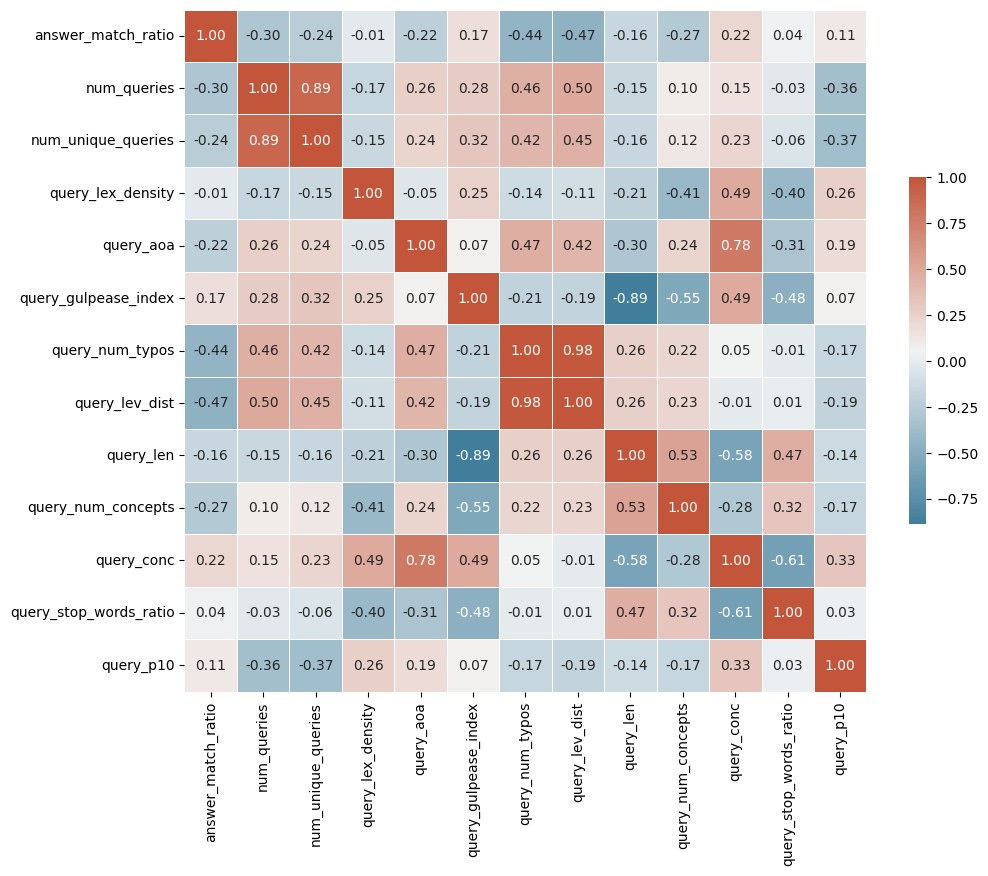

In [20]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

corr = final_answers_queries.drop(columns=["uid", "topic_number", "prompt", "answer", "TaskStartTime", "TaskEndTime", "TaskDuration", "matched_keywords", "num_answer_matches"], inplace=False).corr(method="spearman", numeric_only=True)

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, cmap=cmap,
            square=True, linewidths=.5, cbar_kws={"shrink": .5}, annot=True, fmt=".2f")


### SERP

In [14]:
import pandas as pd

final_answers_serp = pd.read_csv("Data/final_answer_serp.csv")

In [15]:
from scipy.stats import spearmanr

categories = final_answers_serp.drop(columns=["uid", "topic_number", "prompt", "answer", "TaskStartTime", "TaskEndTime", "TaskDuration", "matched_keywords", "num_answer_matches", "answer_match_ratio"])
for category in categories:
    res = spearmanr(final_answers_serp["answer_match_ratio"], final_answers_serp[category], nan_policy="omit")
    print(f"Category: {category}; \tcoefficient: {res.statistic}; \tpval: {res.pvalue}")

Category: SERP_dwell_time; 	coefficient: 0.12124817045329263; 	pval: 0.3824621060762704
Category: snippet_dwell_time; 	coefficient: 0.005873456248019057; 	pval: 0.9663780569506728
Category: view_depth; 	coefficient: 0.10032913513141196; 	pval: 0.47039361603030927
Category: view_repeat; 	coefficient: -0.05477303674590413; 	pval: 0.6940421462405548
Category: unique_view_count; 	coefficient: 0.01963918547798906; 	pval: 0.8879058041238183


<Axes: >

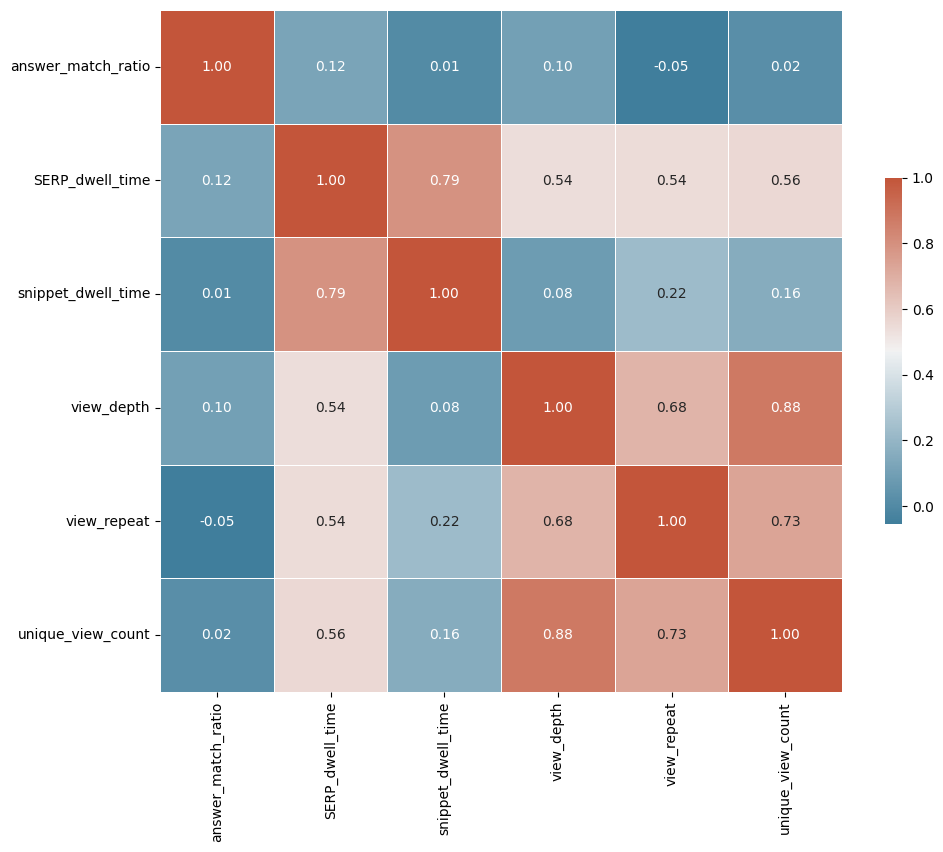

In [16]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

corr = final_answers_serp.drop(columns=["uid", "topic_number", "prompt", "answer", "TaskStartTime", "TaskEndTime", "TaskDuration", "matched_keywords", "num_answer_matches"], inplace=False).corr(method="spearman", numeric_only=True)

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, cmap=cmap,
            square=True, linewidths=.5, cbar_kws={"shrink": .5}, annot=True, fmt=".2f")


### Pages

In [21]:
import pandas as pd

final_answers_pages = pd.read_csv("Data/final_answer_pages.csv")

In [22]:
from scipy.stats import spearmanr

categories = final_answers_pages.drop(columns=["uid", "topic_number", "prompt", "answer", "TaskStartTime", "TaskEndTime", "TaskDuration", "matched_keywords", "num_answer_matches", "answer_match_ratio"])
for category in categories:
    res = spearmanr(final_answers_pages["answer_match_ratio"], final_answers_pages[category], nan_policy="omit")
    print(f"Category: {category}; \tcoefficient: {res.statistic}; \tpval: {res.pvalue}")

Category: page_repeats; 	coefficient: 0.04785970546665064; 	pval: 0.7605459800811804
Category: num_unique_explored_pages; 	coefficient: 0.10109106004247065; 	pval: 0.46701232540169957
Category: click_accuracy; 	coefficient: -0.06179010469861052; 	pval: 0.693860355544619
Category: click_recall; 	coefficient: 0.18216777800342263; 	pval: 0.18737181043041873
Category: page_dwell_time; 	coefficient: 0.35591330722567477; 	pval: 0.01916087938322075
Category: rel_page_dwell_time; 	coefficient: 0.38084179551295366; 	pval: 0.011752017248843649
Category: irrel_page_dwell_time; 	coefficient: 0.4495833650450182; 	pval: 0.10677611955980497
Category: ratio_rel_total_page_dwell_time; 	coefficient: -0.05823260756188073; 	pval: 0.7106974381923403
Category: page_aoa; 	coefficient: 0.08106396114048672; 	pval: 0.6053237922682415
Category: page_len; 	coefficient: 0.17560822143691956; 	pval: 0.2600013965015384
Category: page_conc; 	coefficient: 0.1556610220102155; 	pval: 0.31888487635740764
Category: page_gu

<Axes: >

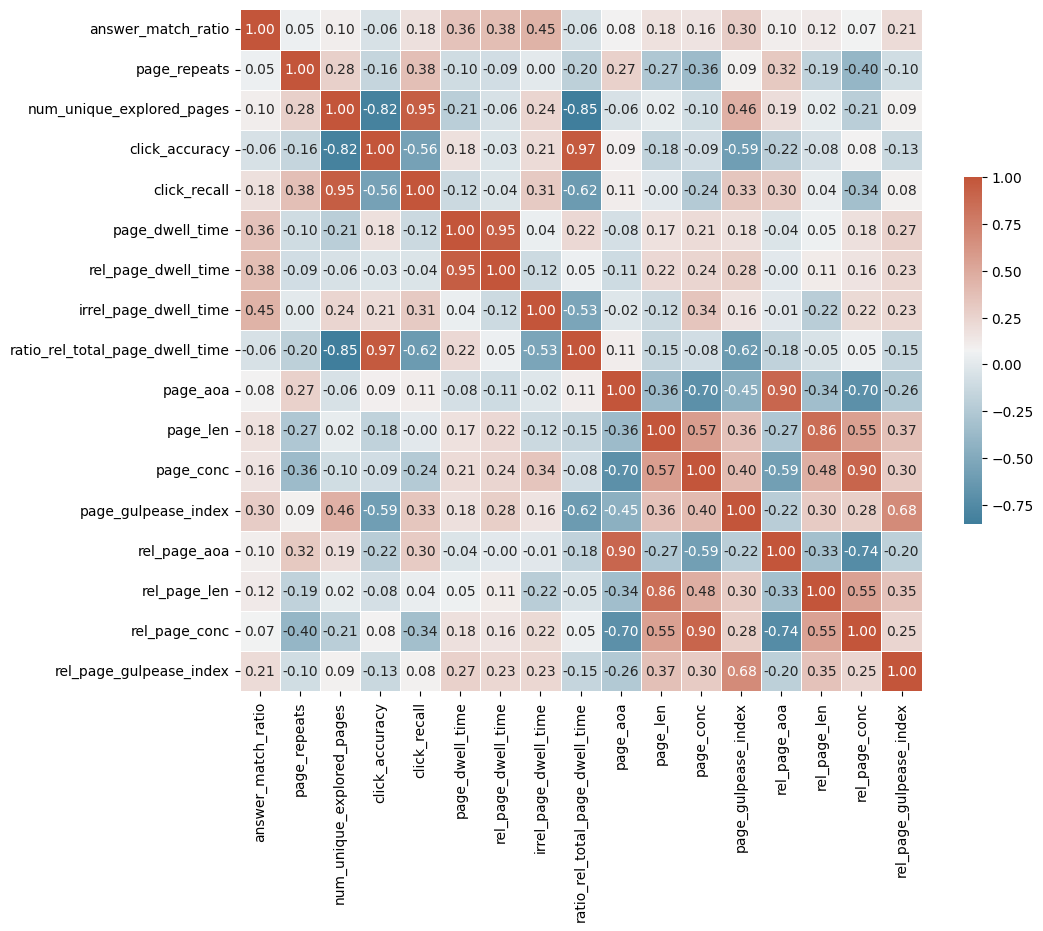

In [23]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

corr = final_answers_pages.drop(columns=["uid", "topic_number", "prompt", "answer", "TaskStartTime", "TaskEndTime", "TaskDuration", "matched_keywords", "num_answer_matches"], inplace=False).corr(method="spearman", numeric_only=True)

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, cmap=cmap,
            square=True, linewidths=.5, cbar_kws={"shrink": .5}, annot=True, fmt=".2f")


### All together

In [11]:
final_answers_combined = pd.merge(final_answers_queries, final_answers_pages, on=["uid", "topic_number", "prompt", "answer", "TaskStartTime", "TaskEndTime", "TaskDuration", "matched_keywords", "num_answer_matches", "answer_match_ratio"])
final_answers_combined.to_csv("Results/final_answers_combined.csv", index=False, encoding="utf8")
final_answers_combined.head()

,uid,topic_number,prompt,answer,TaskStartTime,TaskEndTime,TaskDuration,num_answer_matches,matched_keywords,answer_match_ratio,...,num_unique_explored_pages,click_accuracy,page_dwell_time,rel_page_dwell_time,irrel_page_dwell_time,page_aoa,page_len,page_conc,page_gulpease_index,user_category_y
0,1,g3t3,Quali sono 5 animali tipici dell'India?,Rinoceronte tigre Leone stambecco cervo,2026-05-19 14:48:04.522,2026-05-19 14:56:19.153,8.243850,4,"['tigre', 'rinoceronte', 'leone', 'cervo']",0.8,...,1,1.0,128.0225,128.0225,NaN,5.314087,1389.0,6.307500,51.666813,0
1,1,g3t2,Qual è il nome del simbolo al centro della ban...,Il simbolo della bandiera rappresenta una ruota,2026-05-19 14:56:45.133,2026-05-19 15:06:18.848,9.561917,1,['ruota'],0.5,...,1,1.0,209.6020,209.6020,NaN,5.521524,1116.0,6.177326,43.901500,0
2,1,g3t1,Come si chiama il fiume sacro agli indiani?,Il fiume gange,2026-05-19 15:06:45.708,2026-05-19 15:10:10.812,3.418400,1,['gange'],1.0,...,1,1.0,36.1120,36.1120,NaN,5.207799,2037.0,6.622689,49.490058,1
3,2,g3t3,Quali sono 5 animali tipici dell'India?,"Tigre,leone,rinoceronte,barasingha,blackbuck.",2026-05-19 14:48:38.961,2026-05-19 14:58:07.578,9.476950,5,"['tigre', 'rinoceronte', 'leone', 'barasingha'...",1.0,...,1,1.0,313.3040,313.3040,NaN,5.314087,1389.0,6.307500,51.666813,1
4,2,g3t2,Qual è il nome del simbolo al centro della ban...,Ruota,2026-05-19 14:58:35.224,2026-05-19 15:10:30.790,11.926100,1,['ruota'],0.5,...,1,1.0,64.6990,64.6990,NaN,5.055281,867.0,6.343939,50.562343,0


<Axes: >

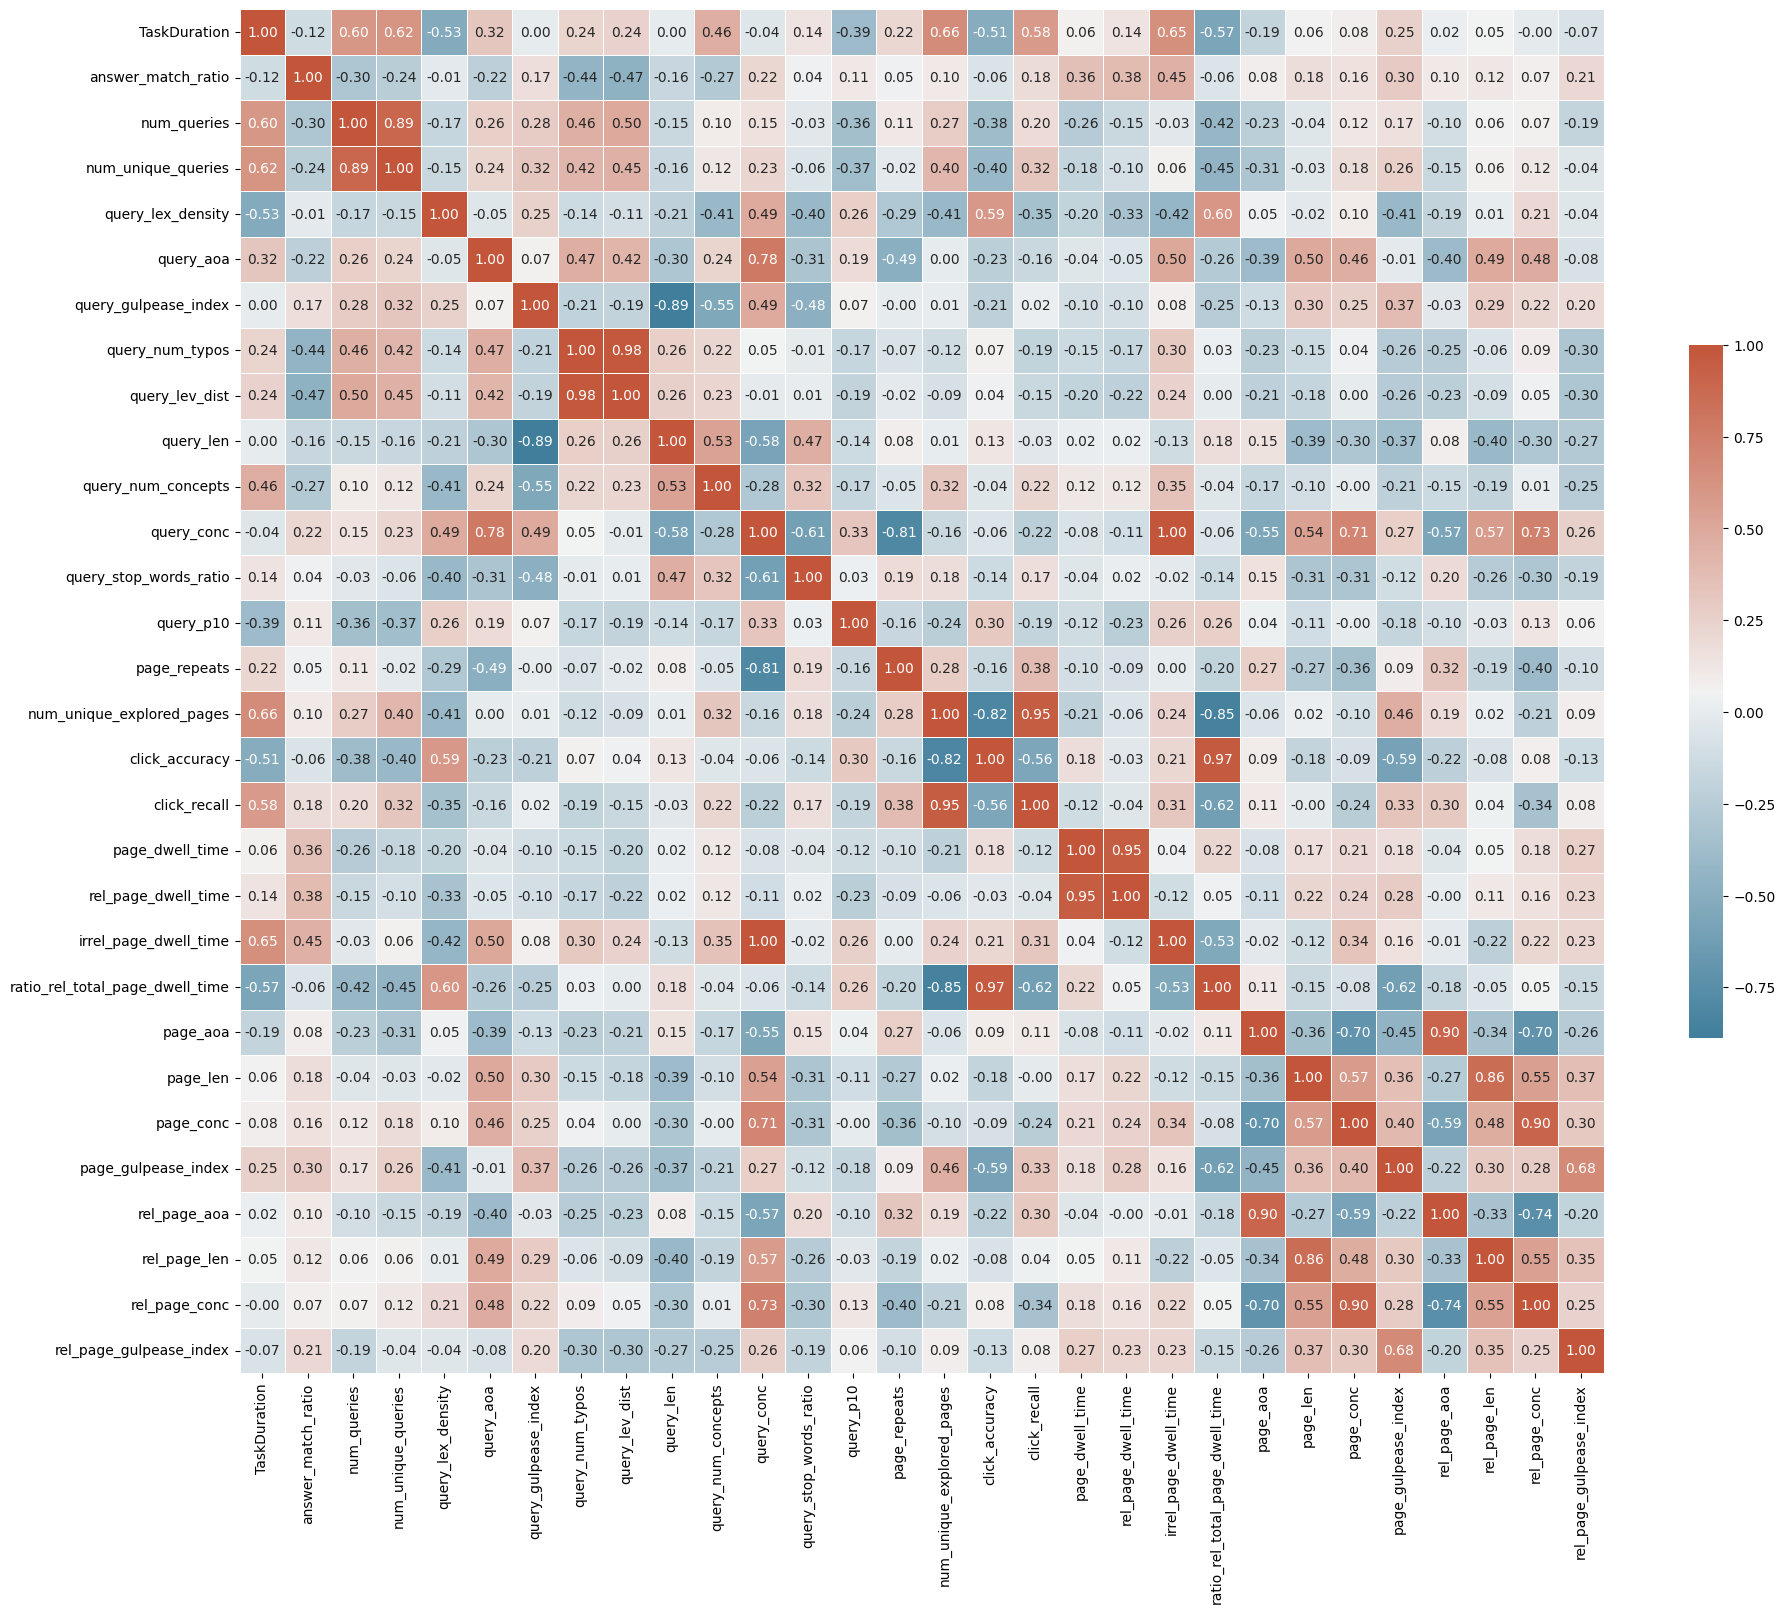

In [ ]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

corr = final_answers_combined.drop(columns=["uid", "topic_number", "prompt", "answer", "TaskStartTime", "TaskEndTime", "matched_keywords", "num_answer_matches"], inplace=False).corr(method="spearman", numeric_only=True)

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(22, 18))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, cmap=cmap,
            square=True, linewidths=.5, cbar_kws={"shrink": .5}, annot=True, fmt=".2f")


### Radar plots

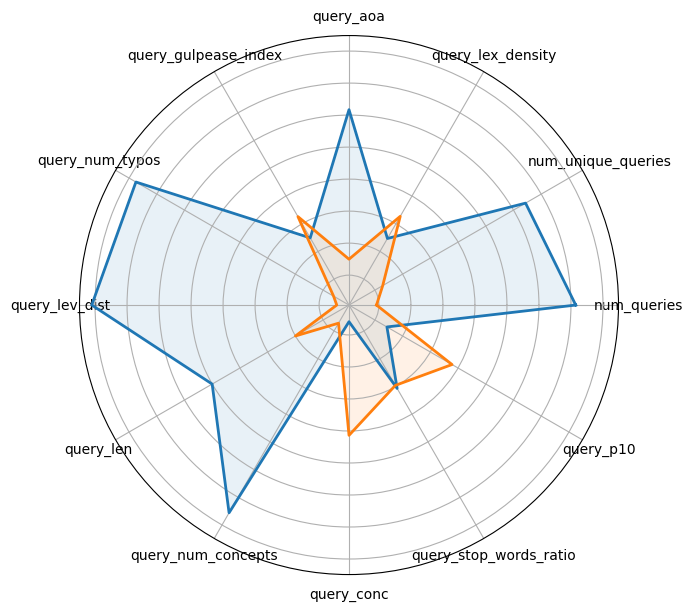

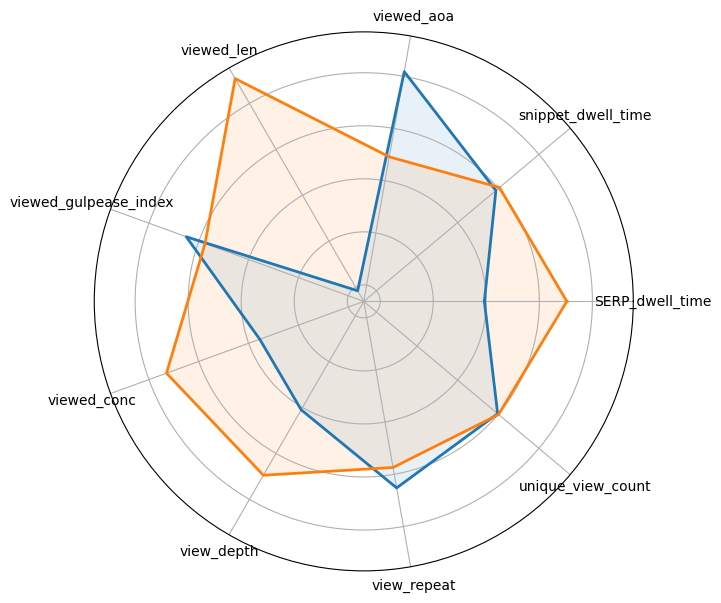

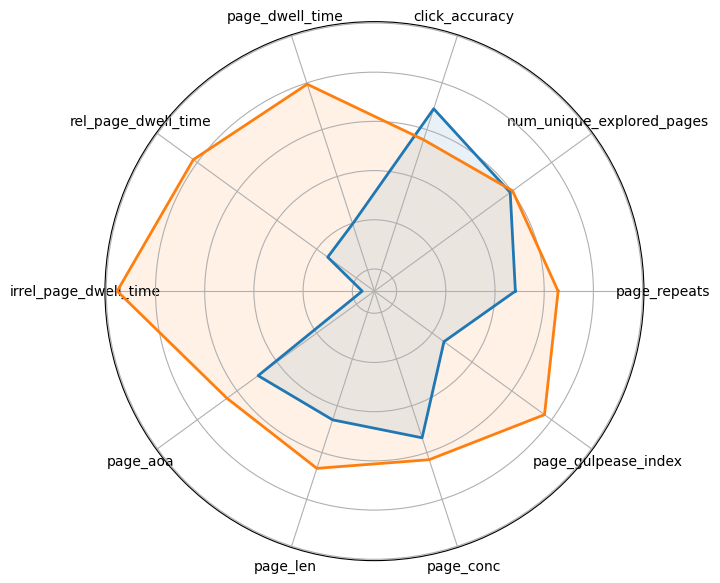

In [ ]:
from driver import get_radar_plot
import pandas as pd

final_answers_queries = pd.read_csv("Data/final_answer_queries.csv")
final_answers_serp = pd.read_csv("Data/final_answer_serp.csv")
final_answers_pages = pd.read_csv("Data/final_answer_pages.csv")
final_answers_pages = final_answers_pages.drop(columns = ["rel_page_gulpease_index", "rel_page_conc", "rel_page_len", "rel_page_aoa", "ratio_rel_total_page_dwell_time", "click_recall"])

final_answers_combined = pd.merge(final_answers_queries, final_answers_pages, on=["uid", "topic_number", "prompt", "answer", "TaskStartTime", "TaskEndTime", "TaskDuration", "matched_keywords", "num_answer_matches", "answer_match_ratio"])

for df_name in [
    final_answers_queries, 
    final_answers_serp,
    final_answers_pages,
    ]:

    final_answers_trial = df_name

    user_category = []

    for _, row in final_answers_trial.iterrows():
        if row["answer_match_ratio"] == 1:
            user_category.append(1)
        else:
            user_category.append(0)

    final_answers_trial["user_category"] = user_category

    categories = final_answers_trial.drop(columns=["uid", "topic_number", "prompt", "answer", "TaskStartTime", "TaskEndTime", "matched_keywords", "num_answer_matches", "answer_match_ratio", "user_category", "TaskDuration"])
    get_radar_plot(df=final_answers_trial, search_stage="final_answer", categories=list(categories.columns), artefact="session", group = "user_category")

In [7]:
import pandas as pd

final_answers_queries = pd.read_csv("Data/final_answer_queries.csv")
final_answers_serp = pd.read_csv("Data/final_answer_serp.csv")
final_answers_pages = pd.read_csv("Data/final_answer_pages.csv")

final_answers_combined = pd.merge(final_answers_queries, final_answers_serp, on=["uid", "topic_number", "prompt", "answer", "TaskStartTime", "TaskEndTime", "TaskDuration", "matched_keywords", "num_answer_matches", "answer_match_ratio"])
final_answers_combined = pd.merge(final_answers_combined, final_answers_pages, on = ["uid", "topic_number", "prompt", "answer", "TaskStartTime", "TaskEndTime", "TaskDuration", "matched_keywords", "num_answer_matches", "answer_match_ratio"])
final_answers_combined.to_csv("Data/final_answer_combined.csv", index=False, encoding="utf8")

In [8]:
final_answers_combined.head()

,uid,topic_number,prompt,answer,TaskStartTime,TaskEndTime,TaskDuration,num_answer_matches,matched_keywords,answer_match_ratio,...,irrel_page_dwell_time,ratio_rel_total_page_dwell_time,page_aoa,page_len,page_conc,page_gulpease_index,rel_page_aoa,rel_page_len,rel_page_conc,rel_page_gulpease_index
0,1,g3t3,Quali sono 5 animali tipici dell'India?,Rinoceronte tigre Leone stambecco cervo,2026-05-19 14:48:04.522,2026-05-19 14:56:19.153,8.243850,4,"['tigre', 'rinoceronte', 'leone', 'cervo']",0.8,...,NaN,1.0,5.314087,1389.0,6.307500,51.666813,5.314087,1389.0,6.307500,51.666813
1,1,g3t2,Qual è il nome del simbolo al centro della ban...,Il simbolo della bandiera rappresenta una ruota,2026-05-19 14:56:45.133,2026-05-19 15:06:18.848,9.561917,1,['ruota'],0.5,...,NaN,1.0,5.521524,1116.0,6.177326,43.901500,5.521524,1116.0,6.177326,43.901500
2,1,g3t1,Come si chiama il fiume sacro agli indiani?,Il fiume gange,2026-05-19 15:06:45.708,2026-05-19 15:10:10.812,3.418400,1,['gange'],1.0,...,NaN,1.0,5.207799,2037.0,6.622689,49.490058,5.207799,2037.0,6.622689,49.490058
3,2,g3t3,Quali sono 5 animali tipici dell'India?,"Tigre,leone,rinoceronte,barasingha,blackbuck.",2026-05-19 14:48:38.961,2026-05-19 14:58:07.578,9.476950,5,"['tigre', 'rinoceronte', 'leone', 'barasingha'...",1.0,...,NaN,1.0,5.314087,1389.0,6.307500,51.666813,5.314087,1389.0,6.307500,51.666813
4,2,g3t2,Qual è il nome del simbolo al centro della ban...,Ruota,2026-05-19 14:58:35.224,2026-05-19 15:10:30.790,11.926100,1,['ruota'],0.5,...,NaN,1.0,5.055281,867.0,6.343939,50.562343,5.055281,867.0,6.343939,50.562343


In [27]:
import pandas as pd

final_answers_combined = pd.read_csv("Data/final_answer_combined.csv")
query_formulation = pd.read_csv("Data/query_formulation_df.csv")
navigation_quality = pd.read_csv("Data/navigation_quality.csv")
information_distillation = pd.read_csv("Data/information_distillation_df.csv")
final_answers_raw = pd.read_csv("Data/final_answer_df.csv")

avg_query_eff = []
avg_nav_eff = []
avg_distill_eff = []
success_category = []

for _, row in final_answers_combined.iterrows():
    session_queries = query_formulation.loc[(query_formulation["uid"]==row["uid"]) & (query_formulation["topic_number"]==row["topic_number"])]
    session_serp_navs = navigation_quality.loc[(navigation_quality["uid"]==row["uid"]) & (navigation_quality["topic_number"]==row["topic_number"])]
    session_explored_pages = information_distillation.loc[(information_distillation["uid"]==row["uid"]) & (information_distillation["topic_number"]==row["topic_number"])]

    avg_query_eff.append(session_queries["effective_query"].mean())
    avg_nav_eff.append(session_serp_navs["effective_navigation"].mean())
    avg_distill_eff.append(session_explored_pages["effective_distillation"].mean())

    if row["answer_match_ratio"] == 0:
        success_category.append("fail")
    elif row["answer_match_ratio"] == 1:
        success_category.append("success")
    else:
        success_category.append("part success")

final_answers_combined["avg_query_eff"] = avg_query_eff
final_answers_combined["avg_nav_eff"] = avg_nav_eff
final_answers_combined["avg_distill_eff"] = avg_distill_eff
final_answers_combined["success_category"] = success_category

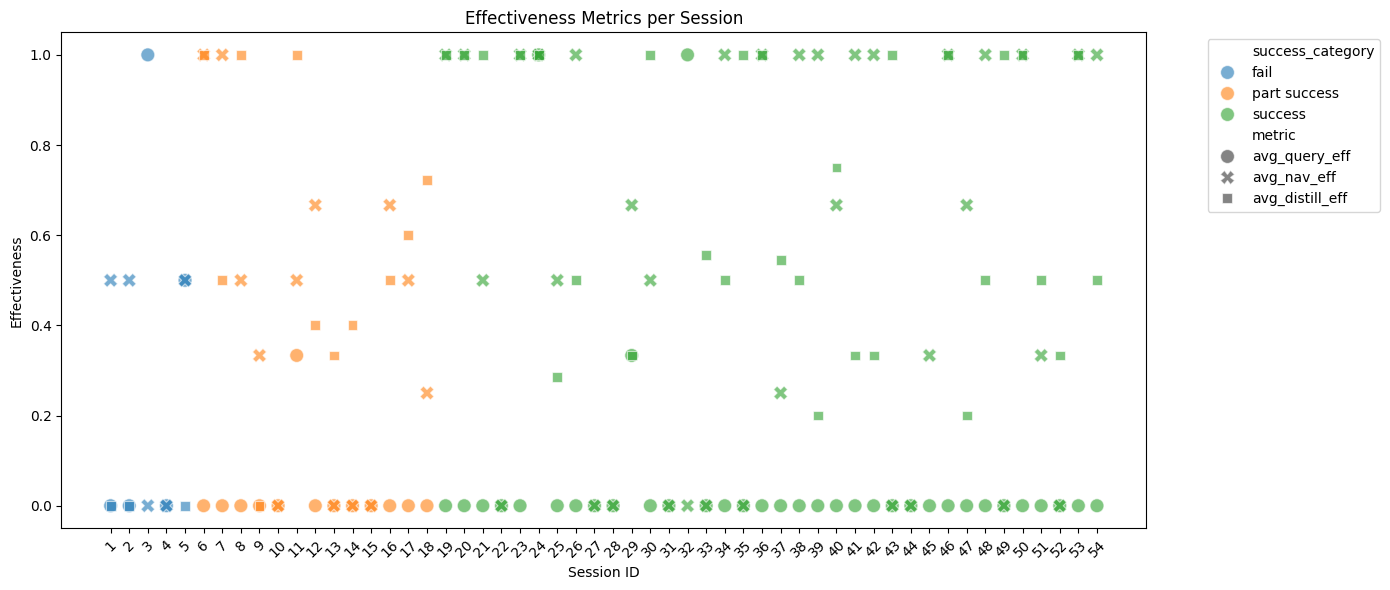

In [29]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

final_answers_combined = final_answers_combined.sort_values(by=["success_category", "uid", "topic_number"], ignore_index=True)

# Create row index for x-axis
df_plot = final_answers_combined.reset_index(names="row_id")

# Reshape to long format
df_long = df_plot.melt(
    id_vars=["row_id", "success_category"],
    value_vars=["avg_query_eff", "avg_nav_eff", "avg_distill_eff"],
    var_name="metric",
    value_name="effectiveness"
)

plt.figure(figsize=(14, 6))

sns.scatterplot(
    data=df_long,
    x="row_id",
    y="effectiveness",
    hue="success_category",   # color by success category
    style="metric",           # marker by metric
    s=100,
    alpha=0.6
)

plt.xticks(
    ticks=df_plot["row_id"],
    labels=df_plot["row_id"]+1,
    rotation=45
)

plt.xlabel("Session ID")
plt.ylabel("Effectiveness")
plt.title("Effectiveness Metrics per Session")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()

plt.show()

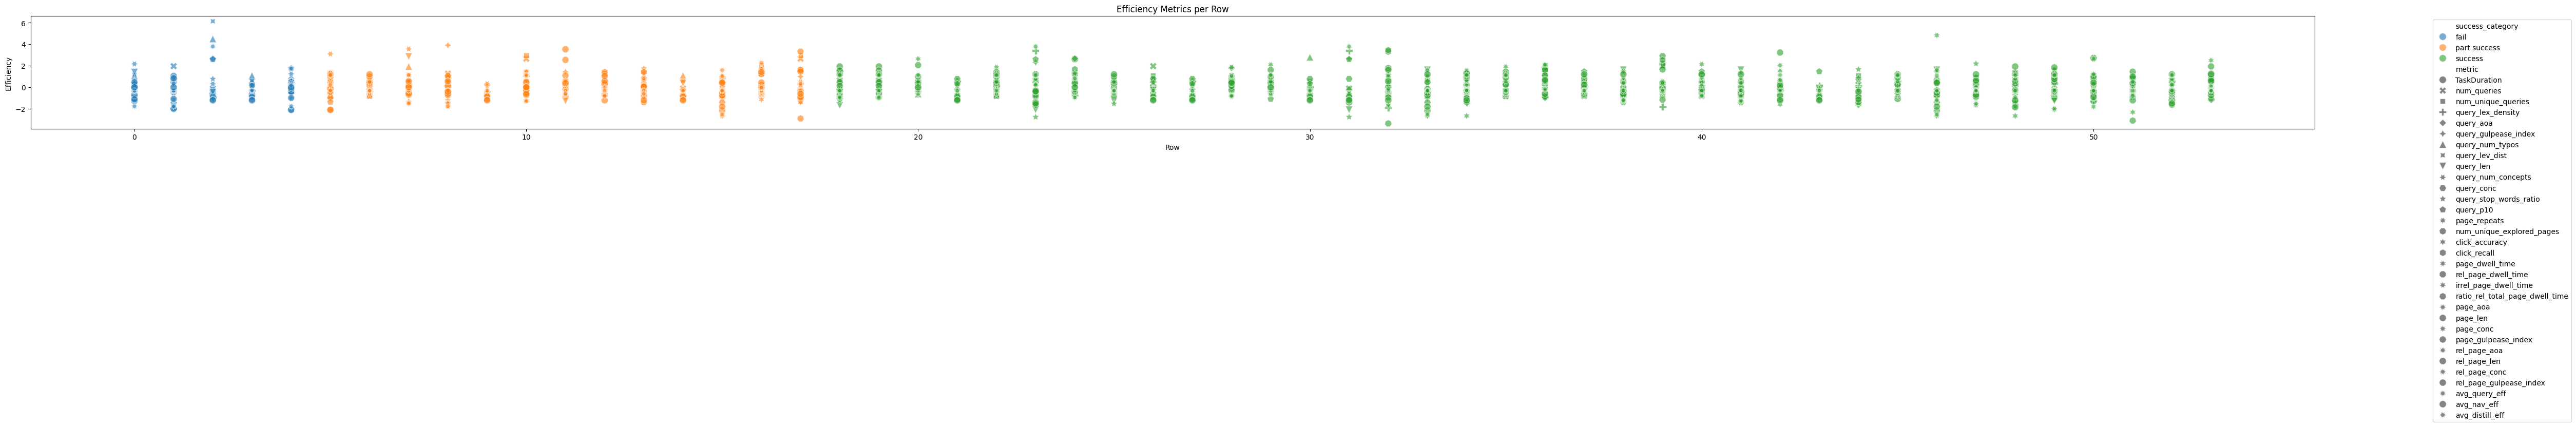

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import zscore
from sklearn.preprocessing import MinMaxScaler

categories = list(final_answers_combined.drop(columns=["uid", "topic_number", "prompt", "answer", "TaskStartTime", "TaskEndTime", "matched_keywords", "num_answer_matches", "answer_match_ratio", "success_category"]).columns)
final_answers_combined = final_answers_combined.sort_values(by=["success_category", "uid", "topic_number"], ignore_index=True)
final_answers_combined[categories] = final_answers_combined[categories].apply(zscore, nan_policy="omit", ddof=1)

# Create row index for x-axis
df_plot = final_answers_combined.reset_index(names="row_id")

# Convert to long format
df_long = df_plot.melt(
    id_vars=["row_id", "success_category"],
    value_vars=categories,
    var_name="metric",
    value_name="efficiency"
)

# df_long

plt.figure(figsize=(50, 6))

sns.scatterplot(
    data=df_long,
    x="row_id",
    y="efficiency",
    hue="success_category",   # color by success category
    style="metric",           # marker by metric
    s=100,
    alpha=0.6
)

plt.xlabel("Row")
plt.ylabel("Efficiency")
plt.title("Efficiency Metrics per Row")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()

plt.show()